# Criação dos atributos

As transformações são implementadas em `ml/features.py`. Nenhuma coluna do gabarito é lida por essa etapa. O histórico é agregado por parceiro e tipo de transação, excluindo o dia inteiro do lançamento atual: a fonte não tem horários que permitam ordenar eventos dentro do dia.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ml").is_dir() and (p / "sql").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from ml.data import load_tables
from ml.plotting import configure_style, style_table, save_figure
from ml.config import REPORTS, ARTIFACTS
get_ipython().run_line_magic("matplotlib", "inline")
configure_style()
pd.set_option("display.max_columns", 40)


In [2]:
from ml.experiment import prepare_features
from ml.features import MODEL_FEATURES
features = prepare_features()
display(style_table(pd.read_csv(REPORTS / "dicionario_atributos.csv")))


atributo,entra_no_modelo,grupo
id_transacao_natural,False,transacao/calendario/diagnostico
data,False,transacao/calendario/diagnostico
id_parceiro_natural,False,transacao/calendario/diagnostico
valor_bruto,False,transacao/calendario/diagnostico
tipo_transacao,True,transacao/calendario/diagnostico
id_area_natural,True,transacao/calendario/diagnostico
id_categoria_natural,True,transacao/calendario/diagnostico
log_valor,True,transacao/calendario/diagnostico
qtd_historico,False,historico anterior ao dia
media_log_historico,False,historico anterior ao dia


## Contrato dos atributos

- `log_valor`: log(1 + valor bruto), sem consultar a distribuição futura.
- `desvio_log_*`: valor log atual menos média log histórica.
- `z_*`: desvio absoluto dividido pelo desvio padrão histórico, com piso fixo 0,15.
- Histórico completo e janela de 90 dias: contagens, médias e dispersão usam só dias anteriores.
- Frequência e intervalo desde a última ocorrência; flag de ausência de histórico.
- Calendário cíclico: seno e cosseno de mês/dia da semana.
- Contexto categórico: tipo, área e categoria, codificados no treino.

**Sem histórico:** os desvios são zero e há uma flag explícita; isso limita a detecção de parceiros novos. A janela de 90 dias não é um rótulo. IDs e estatísticas auxiliares permanecem para rastreabilidade, mas a matriz usa apenas a lista explícita `MODEL_FEATURES`.

Pré-processamento (padronização e one-hot) só será ajustado no treino. Variáveis redundantes são mantidas neste primeiro experimento fixo; a matriz de correlação documenta essa decisão.

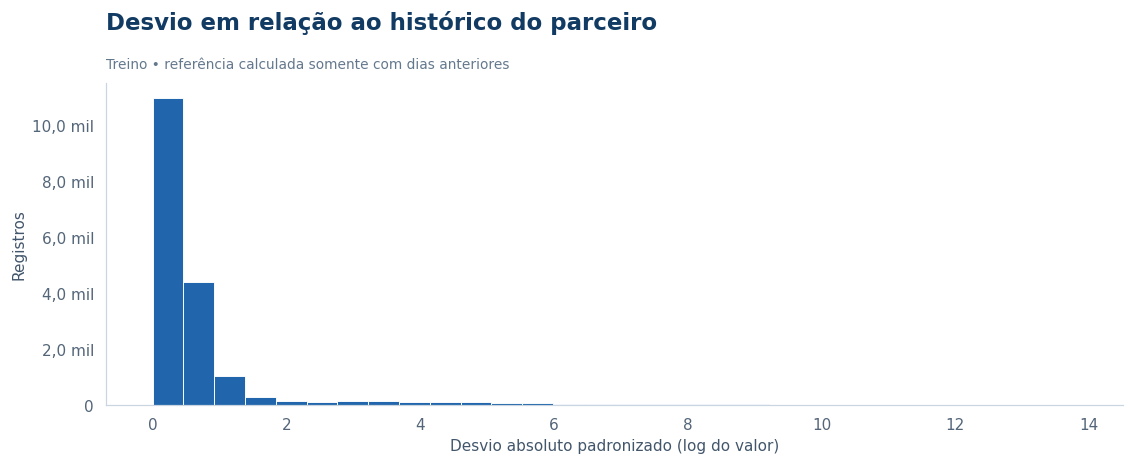

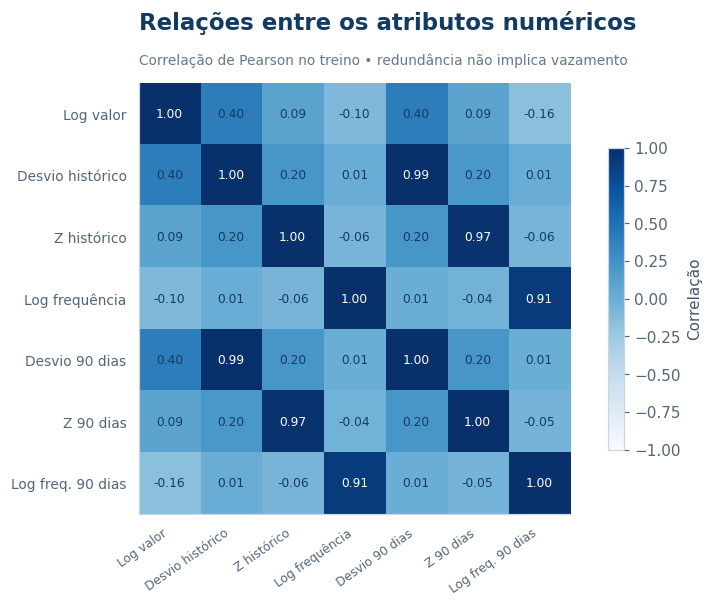

In [3]:
from ml.diagnostics import feature_figures
figures = feature_figures(features)
for i, figure in enumerate(figures, 1):
    save_figure(figure, f"atributos_{i:02d}", "experimento")
    display(figure)
    plt.close(figure)


In [4]:
display(style_table(features[["id_transacao_natural", "data", "valor_bruto", "qtd_historico", "media_log_historico", "z_historico", "sem_historico"]].head(8).round(3)))
print(f"Arquivo: ml/artifacts/features.csv • {len(features):,} linhas • {len(MODEL_FEATURES)} atributos de entrada")


id_transacao_natural,data,valor_bruto,qtd_historico,media_log_historico,z_historico,sem_historico
TR-02455,2024-01-01 00:00:00,4042.190000,0,nan,0.000000,1
TR-07251,2024-01-01 00:00:00,2012.790000,0,nan,0.000000,1
TR-22846,2024-01-01 00:00:00,3242.200000,0,nan,0.000000,1
TR-24028,2024-01-01 00:00:00,9053.440000,0,nan,0.000000,1
TR-31430,2024-01-01 00:00:00,6461.610000,0,nan,0.000000,1
TR-32033,2024-01-01 00:00:00,1912.220000,0,nan,0.000000,1
TR-34339,2024-01-01 00:00:00,2687.920000,0,nan,0.000000,1
TR-09434,2024-01-02 00:00:00,6913.490000,0,nan,0.000000,1


Arquivo: ml/artifacts/features.csv • 39,792 linhas • 16 atributos de entrada
